In [8]:
!pip install statsmodels


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from statsmodels.tsa.statespace.sarimax import SARIMAX

import warnings
warnings.filterwarnings("ignore")

In [10]:
df = pd.read_csv("restaurant_sales_data.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 13)


,date,restaurant_id,restaurant_type,menu_item_name,meal_type,key_ingredients_tags,typical_ingredient_cost,observed_market_price,actual_selling_price,quantity_sold,has_promotion,special_event,weather_condition
0,1/1/2024,11,Food Stall,Laksa,Lunch,"rice noodles, fish broth, tamarind, shrimp pas...",4.5,10.59,12.48,361,False,False,Sunny
1,1/1/2024,7,Casual Dining,Spaghetti Carbonara,Dinner,"spaghetti, eggs, cheese, beef bacon, black pepper",9.0,26.64,60.46,105,False,False,Sunny
2,1/1/2024,23,Fine Dining,Beef Rendang,Dinner,"beef, coconut milk, galangal, lemongrass, spic...",9.0,49.42,80.15,36,False,False,Rainy
3,1/1/2024,22,Food Stall,Roti Canai,Dinner,"flour, ghee, egg, water, curry",0.8,2.04,2.48,503,False,False,Sunny
4,1/1/2024,32,Fine Dining,Spaghetti Carbonara,Lunch,"spaghetti, eggs, cheese, beef bacon, black pepper",9.0,40.30,55.54,262,False,False,Rainy


In [11]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Rows: 10000
Columns: 13

Column names:
['date', 'restaurant_id', 'restaurant_type', 'menu_item_name', 'meal_type', 'key_ingredients_tags', 'typical_ingredient_cost', 'observed_market_price', 'actual_selling_price', 'quantity_sold', 'has_promotion', 'special_event', 'weather_condition']

Data types:
date                        object
restaurant_id                int64
restaurant_type             object
menu_item_name              object
meal_type                   object
key_ingredients_tags        object
typical_ingredient_cost    float64
observed_market_price      float64
actual_selling_price       float64
quantity_sold                int64
has_promotion                 bool
special_event                 bool
weather_condition           object
dtype: object


In [12]:
missing = df.isnull().sum()

missing_table = pd.DataFrame({
    "Column": missing.index,
    "Missing_Values": missing.values,
    "Missing_Percentage": 
        (missing.values / len(df)) * 100
})

display(missing_table)

,Column,Missing_Values,Missing_Percentage
0,date,0,0.0
1,restaurant_id,0,0.0
2,restaurant_type,0,0.0
3,menu_item_name,0,0.0
4,meal_type,0,0.0
5,key_ingredients_tags,0,0.0
6,typical_ingredient_cost,0,0.0
7,observed_market_price,0,0.0
8,actual_selling_price,0,0.0
9,quantity_sold,0,0.0


In [13]:
duplicates = df.duplicated().sum()

print("Duplicate records:", duplicates)

Duplicate records: 0


In [14]:
df["date"] = pd.to_datetime(
    df["date"],
    dayfirst=False,
    errors="coerce"
)

In [15]:
print(df["date"].min())
print(df["date"].max())

2024-01-01 00:00:00
2025-01-01 00:00:00


In [16]:
df["revenue"] = (
    df["quantity_sold"] *
    df["actual_selling_price"]
)

In [17]:
df["ingredient_cost"] = (
    df["quantity_sold"] *
    df["typical_ingredient_cost"]
)

In [18]:
df["gross_margin"] = (
    df["revenue"] -
    df["ingredient_cost"]
)

In [19]:
df["margin_percentage"] = np.where(
    df["revenue"] != 0,
    (df["gross_margin"] / df["revenue"]) * 100,
    0
)

In [20]:
#create time variables
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()

df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.day_name()

df["day_number"] = df["date"].dt.dayofweek

df["week"] = df["date"].dt.isocalendar().week

df["quarter"] = df["date"].dt.quarter

df["is_weekend"] = df["day_number"] >= 5

In [21]:
#KPIS

total_demand = df["quantity_sold"].sum()

total_revenue = df["revenue"].sum()

total_cost = df["ingredient_cost"].sum()

total_margin = df["gross_margin"].sum()

average_quantity = df["quantity_sold"].mean()

average_price = df["actual_selling_price"].mean()

average_margin_percentage = df["margin_percentage"].mean()

print("TOTAL DEMAND:", total_demand)
print("TOTAL REVENUE:", round(total_revenue, 2))
print("TOTAL INGREDIENT COST:", round(total_cost, 2))
print("TOTAL GROSS MARGIN:", round(total_margin, 2))
print("AVERAGE QUANTITY SOLD:", round(average_quantity, 2))
print("AVERAGE SELLING PRICE:", round(average_price, 2))
print(
    "AVERAGE MARGIN %:",
    round(average_margin_percentage, 2)
)

TOTAL DEMAND: 2860004
TOTAL REVENUE: 32713418.1
TOTAL INGREDIENT COST: 7828735.2
TOTAL GROSS MARGIN: 24884682.9
AVERAGE QUANTITY SOLD: 286.0
AVERAGE SELLING PRICE: 18.86
AVERAGE MARGIN %: 70.45


In [22]:
#daily demand anlaysis

daily = (
    df.groupby("date")
    .agg(
        demand=("quantity_sold", "sum"),
        revenue=("revenue", "sum"),
        gross_margin=("gross_margin", "sum")
    )
    .reset_index()
)

display(daily.head())

,date,demand,revenue,gross_margin
0,2024-01-01,8479,113363.68,85142.38
1,2024-01-02,7647,92021.47,70549.77
2,2024-01-03,4172,73996.38,59613.78
3,2024-01-04,7592,88740.26,68678.76
4,2024-01-05,6712,77858.61,61094.91


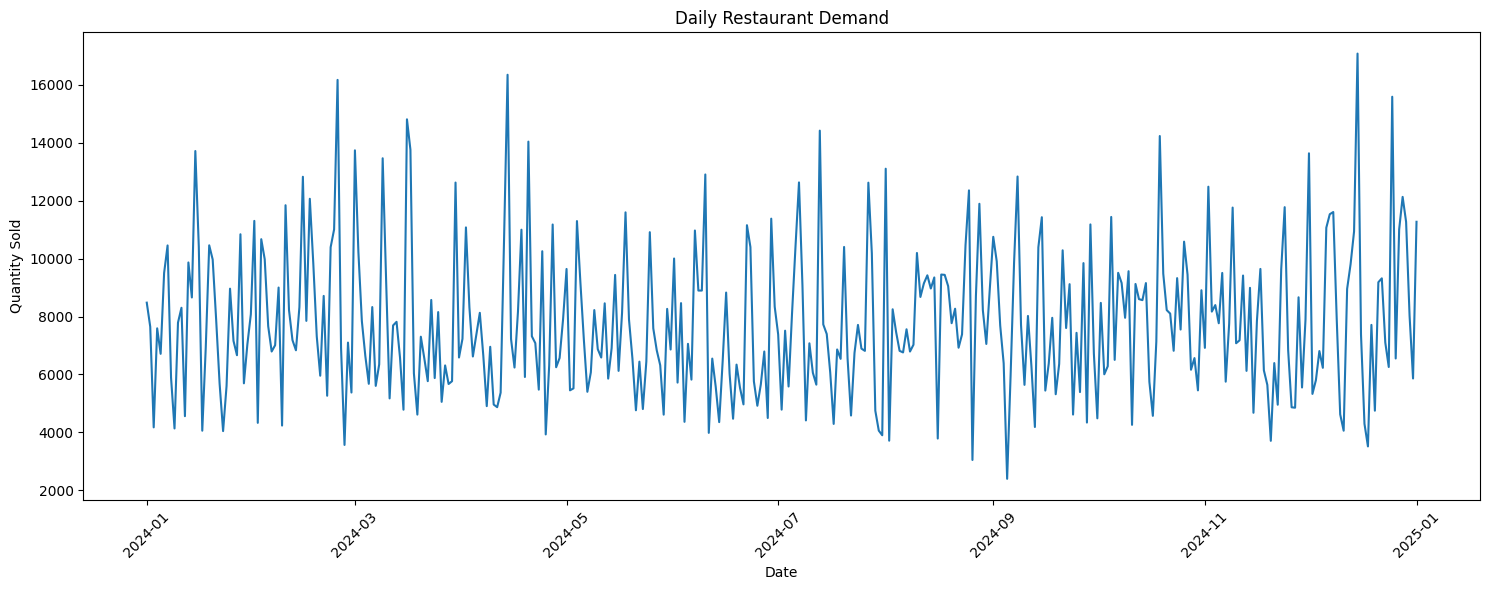

In [23]:
#daily demand trend

plt.figure(figsize=(15,6))

plt.plot(
    daily["date"],
    daily["demand"]
)

plt.title("Daily Restaurant Demand")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

,sum,mean
day_of_week,,
Monday,384001,253.801058
Tuesday,333279,240.982646
Wednesday,380958,261.826804
Thursday,369740,262.599432
Friday,349847,245.679073
Saturday,542530,373.900758
Sunday,499649,365.775256


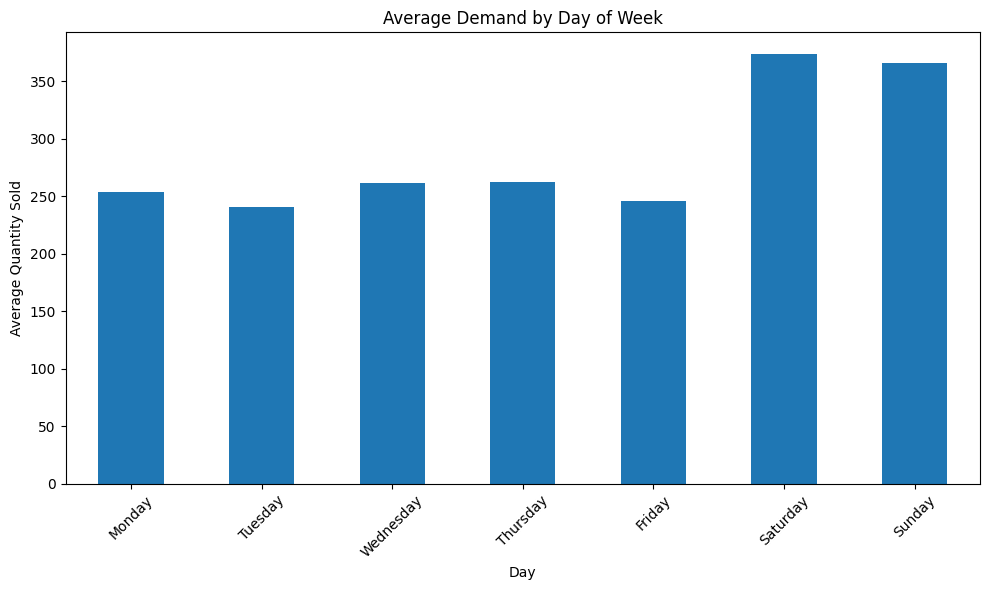

In [24]:
#demand by the day of week

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_analysis = (
    df.groupby("day_of_week")["quantity_sold"]
    .agg(["sum", "mean"])
    .reindex(day_order)
)

display(day_analysis)

plt.figure(figsize=(10,6))

day_analysis["mean"].plot(kind="bar")

plt.title("Average Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Quantity Sold")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

,sum,mean,count
Weekday,1817825,253.073228,7183
Weekend,1042179,369.960596,2817


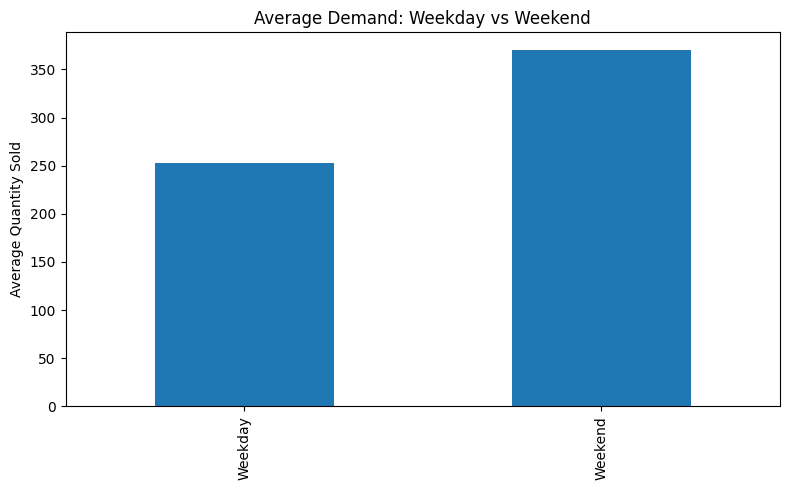

In [25]:
#Weekend vs weekday

weekend_analysis = (
    df.groupby("is_weekend")["quantity_sold"]
    .agg(["sum", "mean", "count"])
)

weekend_analysis.index = [
    "Weekday" if x == False else "Weekend"
    for x in weekend_analysis.index
]

display(weekend_analysis)

plt.figure(figsize=(8,5))

weekend_analysis["mean"].plot(kind="bar")

plt.title("Average Demand: Weekday vs Weekend")
plt.ylabel("Average Quantity Sold")

plt.tight_layout()
plt.show()

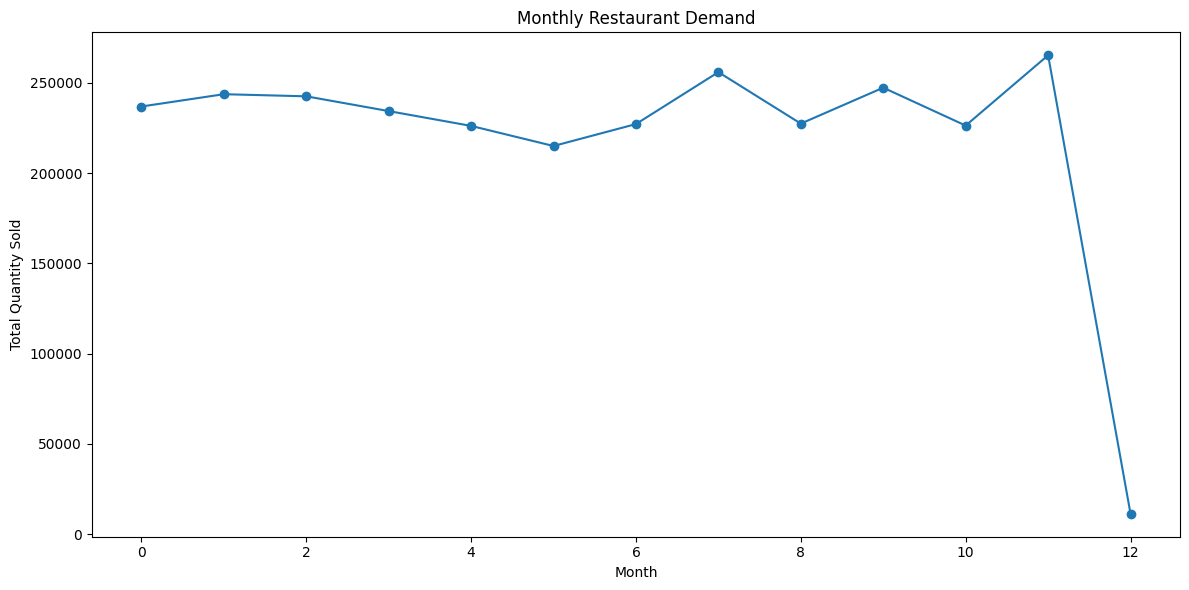

In [26]:
#Monthly demand

monthly = (
    df.groupby(
        ["year", "month", "month_name"]
    )["quantity_sold"]
    .sum()
    .reset_index()
)

monthly

plt.figure(figsize=(12,6))

plt.plot(
    range(len(monthly)),
    monthly["quantity_sold"],
    marker="o"
)

plt.title("Monthly Restaurant Demand")
plt.xlabel("Month")
plt.ylabel("Total Quantity Sold")

plt.tight_layout()
plt.show()

In [27]:
#Seasonal analysis

def assign_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Spring"

    elif month in [6, 7, 8]:
        return "Summer"

    else:
        return "Autumn"


df["season"] = df["month"].apply(assign_season)
season_analysis = (
    df.groupby("season")["quantity_sold"]
    .agg(["sum", "mean", "count"])
)

display(season_analysis)

,sum,mean,count
season,,,
Autumn,701208,285.973899,2452
Spring,703206,278.387173,2526
Summer,698275,282.473706,2472
Winter,757315,296.986275,2550


,demand,average_demand,revenue,margin
restaurant_type,,,,
Food Stall,1358811,311.511004,9686508.42,6511692.82
Casual Dining,715603,300.547249,8900088.14,6954144.94
Cafe,380311,276.791121,4470601.32,3362215.82
Fine Dining,333260,200.036014,9061344.85,7643011.55
Kopitiam,72019,331.884793,594875.37,413617.77


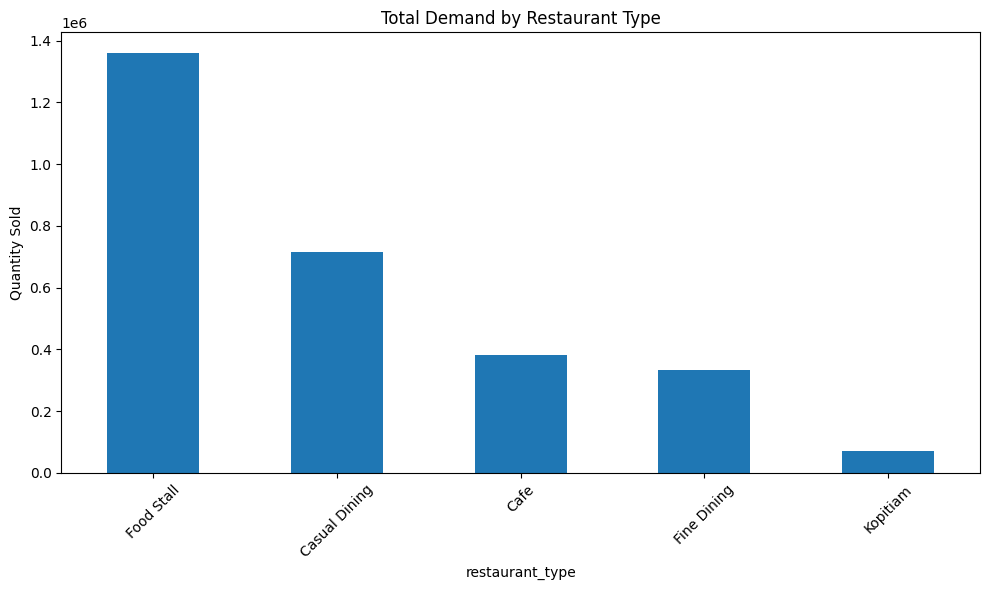

In [28]:
#Restaurant type analysis

restaurant_analysis = (
    df.groupby("restaurant_type")
    .agg(
        demand=("quantity_sold", "sum"),
        average_demand=("quantity_sold", "mean"),
        revenue=("revenue", "sum"),
        margin=("gross_margin", "sum")
    )
    .sort_values(
        "demand",
        ascending=False
    )
)

display(restaurant_analysis)

plt.figure(figsize=(10,6))

restaurant_analysis["demand"].plot(
    kind="bar"
)

plt.title("Total Demand by Restaurant Type")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [29]:
#Menu-item demand

menu_analysis = (
    df.groupby("menu_item_name")
    .agg(
        demand=("quantity_sold", "sum"),
        average_demand=("quantity_sold", "mean"),
        revenue=("revenue", "sum"),
        margin=("gross_margin", "sum")
    )
    .sort_values(
        "demand",
        ascending=False
    )
)

display(menu_analysis)

,demand,average_demand,revenue,margin
menu_item_name,,,,
Teh Tarik,643076,560.659111,1954969.69,1376201.29
Kaya Toast Set,544101,437.028916,5240719.63,3717236.83
Cendol,304622,249.894996,2213847.11,1604603.11
Roti Canai,286505,405.814448,662168.77,432964.77
Iced Lemon Tea,235325,347.599705,1400942.30,1118552.30
Nasi Lemak,226795,344.673252,2423090.12,1856102.62
Chicken Chop,109641,158.212121,4762333.00,3885205.00
Spaghetti Carbonara,93114,135.932847,4511648.25,3673622.25
Tandoori Chicken,91048,125.410468,2139956.04,1502620.04


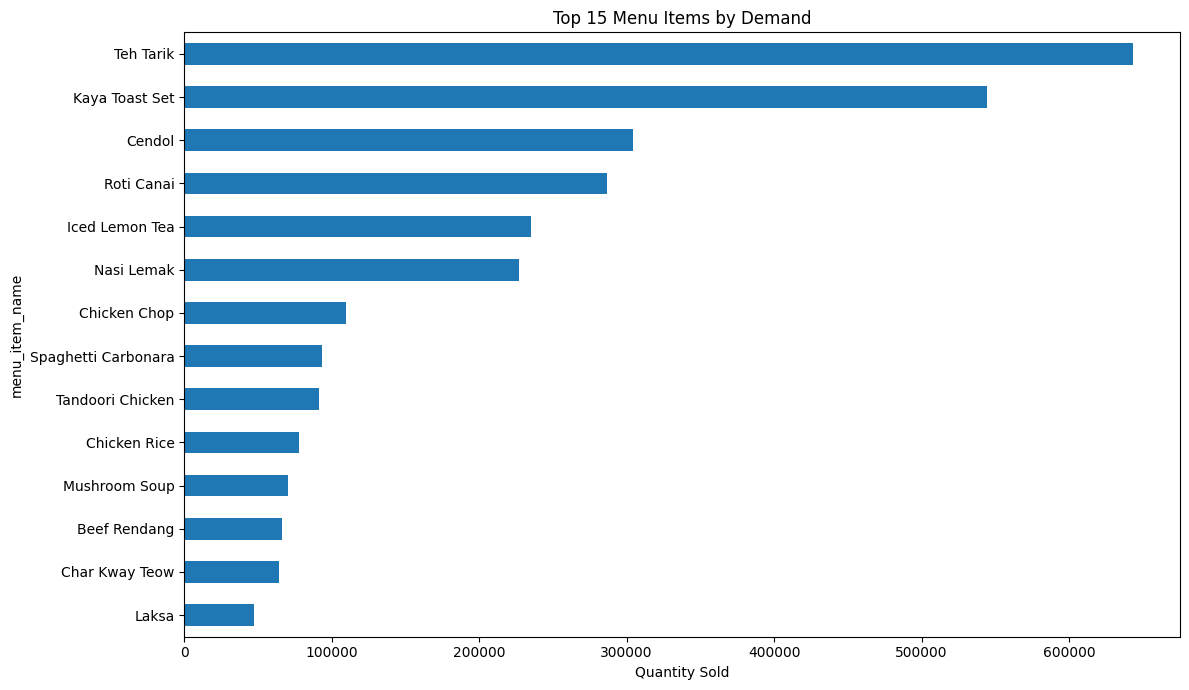

In [30]:
top_menu = menu_analysis.head(15)

plt.figure(figsize=(12,7))

top_menu["demand"].sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Menu Items by Demand")
plt.xlabel("Quantity Sold")

plt.tight_layout()
plt.show()

,demand,average_demand,revenue,margin
meal_type,,,,
Breakfast,1157602,460.279125,8199828.90,5909026.90
Lunch,863103,247.591222,12485901.28,9707189.88
Dinner,839299,209.877219,12027687.92,9268466.12


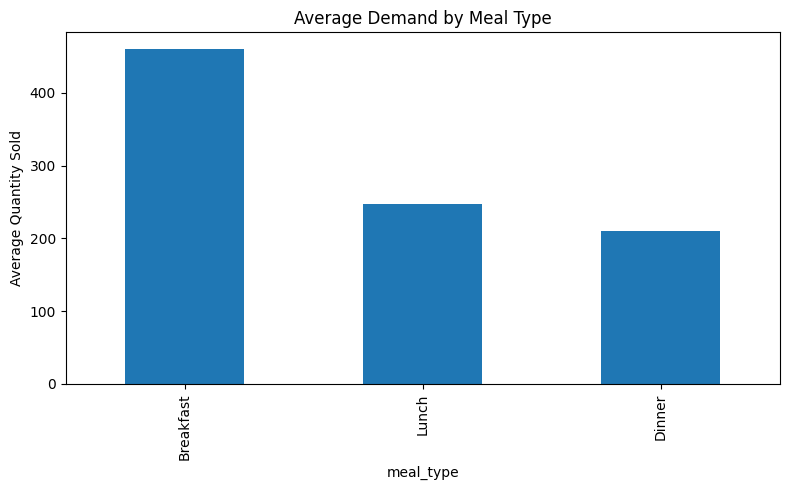

In [31]:
#Meal type analysis

meal_analysis = (
    df.groupby("meal_type")
    .agg(
        demand=("quantity_sold", "sum"),
        average_demand=("quantity_sold", "mean"),
        revenue=("revenue", "sum"),
        margin=("gross_margin", "sum")
    )
    .sort_values(
        "demand",
        ascending=False
    )
)

display(meal_analysis)

plt.figure(figsize=(8,5))

meal_analysis["average_demand"].plot(
    kind="bar"
)

plt.title("Average Demand by Meal Type")
plt.ylabel("Average Quantity Sold")

plt.tight_layout()
plt.show()

In [32]:
#Profitability analysis

item_profitability = (
    df.groupby("menu_item_name")
    .agg(
        demand=("quantity_sold", "sum"),
        revenue=("revenue", "sum"),
        ingredient_cost=("ingredient_cost", "sum"),
        gross_margin=("gross_margin", "sum"),
        average_margin_percentage=(
            "margin_percentage",
            "mean"
        )
    )
    .sort_values(
        "gross_margin",
        ascending=False
    )
)

display(item_profitability)



,demand,revenue,ingredient_cost,gross_margin,average_margin_percentage
menu_item_name,,,,,
Chicken Chop,109641,4762333.00,877128.0,3885205.00,75.964279
Kaya Toast Set,544101,5240719.63,1523482.8,3717236.83,70.468563
Spaghetti Carbonara,93114,4511648.25,838026.0,3673622.25,72.602597
Beef Rendang,66038,2919472.66,594342.0,2325130.66,65.050014
Nasi Lemak,226795,2423090.12,566987.5,1856102.62,74.839147
Cendol,304622,2213847.11,609244.0,1604603.11,71.374166
Tandoori Chicken,91048,2139956.04,637336.0,1502620.04,61.323983
Teh Tarik,643076,1954969.69,578768.4,1376201.29,69.843083
Mushroom Soup,70164,1392304.64,245574.0,1146730.64,69.741145


In [33]:
#Demand level classification

daily["demand_level"] = pd.qcut(
    daily["demand"],
    q=3,
    labels=[
        "Low",
        "Medium",
        "High"
    ]
)

display(
    daily["demand_level"].value_counts()
)

demand_level
Medium    123
Low       122
High      122
Name: count, dtype: int64

In [34]:
#Peak demand identification

peak_days = daily.sort_values(
    "demand",
    ascending=False
).head(10)

display(peak_days)

low_days = daily.sort_values(
    "demand"
).head(10)

display(low_days)

,date,demand,revenue,gross_margin,demand_level
349,2024-12-15,17081,148779.63,106605.03,High
104,2024-04-14,16350,145716.73,109160.03,High
55,2024-02-25,16173,163304.20,119965.20,High
359,2024-12-25,15591,122278.85,90009.55,High
75,2024-03-16,14811,125099.42,91158.12,High
194,2024-07-13,14420,129402.95,95111.25,High
292,2024-10-19,14234,105497.40,77319.30,High
110,2024-04-20,14041,162865.00,122083.00,High
76,2024-03-17,13760,181529.64,136822.34,High
60,2024-03-01,13740,121653.49,89332.39,High


,date,demand,revenue,gross_margin,demand_level
248,2024-09-05,2395,49708.38,39569.48,Low
238,2024-08-26,3046,73921.95,60238.45,Low
352,2024-12-18,3514,56234.96,44259.76,Low
57,2024-02-27,3565,52109.12,39226.02,Low
324,2024-11-20,3707,50207.88,38952.58,Low
214,2024-08-02,3712,67825.45,52730.65,Low
228,2024-08-16,3786,62744.33,49486.83,Low
212,2024-07-31,3899,48806.05,37480.65,Low
115,2024-04-25,3928,44059.47,33521.97,Low
162,2024-06-11,3982,50784.96,39363.96,Low


In [35]:
#forecasting

forecast_data = (
    df.groupby("date")["quantity_sold"]
    .sum()
    .sort_index()
)

forecast_data.head()

date
2024-01-01    8479
2024-01-02    7647
2024-01-03    4172
2024-01-04    7592
2024-01-05    6712
Name: quantity_sold, dtype: int64

In [36]:
#train/test

split_point = int(
    len(forecast_data) * 0.80
)

train = forecast_data.iloc[:split_point]

test = forecast_data.iloc[split_point:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 293
Testing observations: 74


In [37]:
#SARIMA forecasting model

sarima_model = SARIMAX(
    train,
    order=(1,1,1),
    seasonal_order=(1,1,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(
    disp=False
)

print(sarima_fit.summary())

                                     SARIMAX Results                                     
Dep. Variable:                     quantity_sold   No. Observations:                  293
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -2522.213
Date:                           Mon, 21 Sep 2026   AIC                           5054.427
Time:                                   10:12:04   BIC                           5072.529
Sample:                               01-01-2024   HQIC                          5061.691
                                    - 10-19-2024                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0565      0.060     -0.948      0.343      -0.173       0.060
ma.L1         -1.0155      0.021    -47.560

In [38]:
sarima_forecast = sarima_fit.forecast(
    steps=len(test)
)

sarima_forecast.index = test.index

In [39]:
sarima_mae = mean_absolute_error(
    test,
    sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        test,
        sarima_forecast
    )
)

sarima_r2 = r2_score(
    test,
    sarima_forecast
)

sarima_mape = np.mean(
    np.abs(
        (test - sarima_forecast) /
        test.replace(0, np.nan)
    )
) * 100

print("SARIMA Results")
print("----------------------")
print("MAE :", round(sarima_mae, 2))
print("RMSE:", round(sarima_rmse, 2))
print("R²  :", round(sarima_r2, 3))
print("MAPE:", round(sarima_mape, 2), "%")

SARIMA Results
----------------------
MAE : 1747.45
RMSE: 2311.41
R²  : 0.274
MAPE: 23.37 %


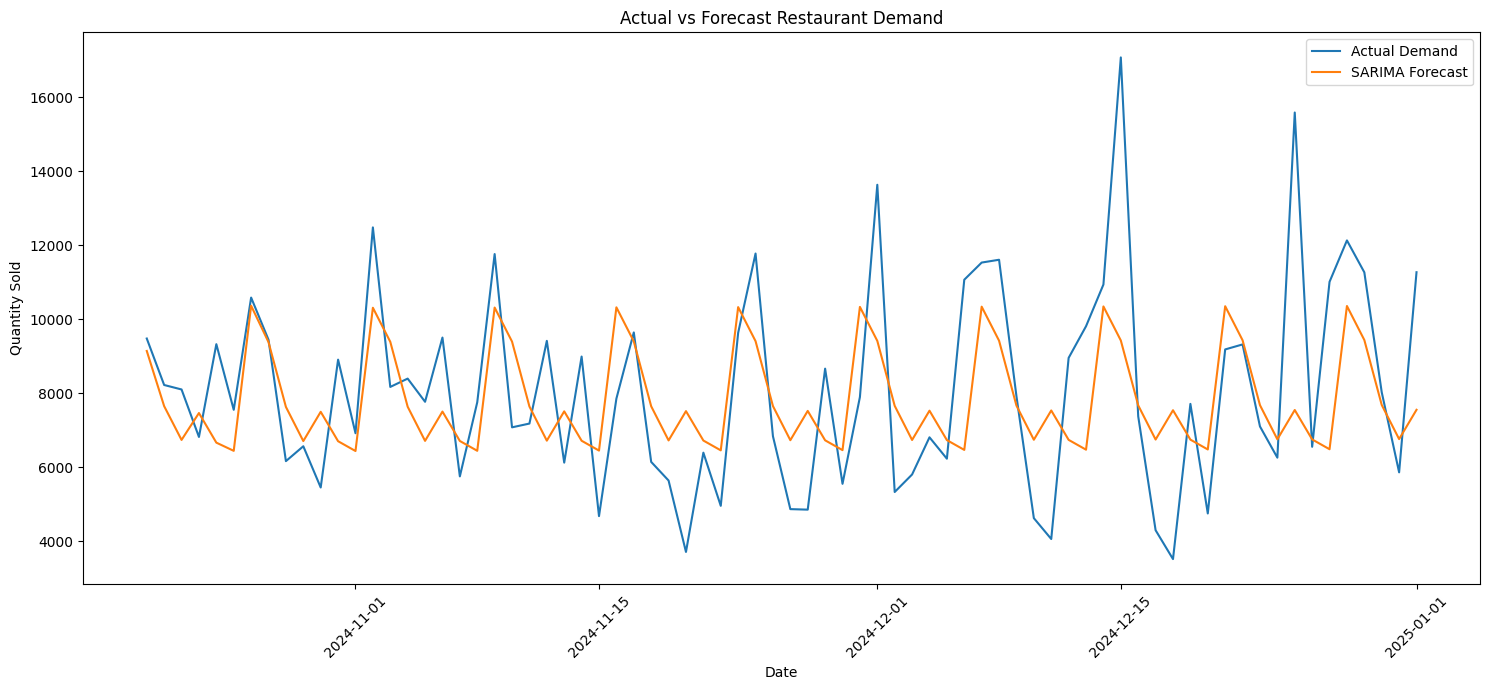

In [40]:
plt.figure(figsize=(15,7))

plt.plot(
    test.index,
    test.values,
    label="Actual Demand"
)

plt.plot(
    sarima_forecast.index,
    sarima_forecast.values,
    label="SARIMA Forecast"
)

plt.title(
    "Actual vs Forecast Restaurant Demand"
)

plt.xlabel("Date")
plt.ylabel("Quantity Sold")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [41]:
#Random Forest forecasting model

ml_data = forecast_data.to_frame(
    name="demand"
)

ml_data["lag_1"] = (
    ml_data["demand"].shift(1)
)

ml_data["lag_7"] = (
    ml_data["demand"].shift(7)
)

ml_data["lag_14"] = (
    ml_data["demand"].shift(14)
)

ml_data["rolling_7"] = (
    ml_data["demand"]
    .rolling(7)
    .mean()
)

ml_data["day_of_week"] = (
    ml_data.index.dayofweek
)

ml_data["month"] = (
    ml_data.index.month
)

ml_data = ml_data.dropna()

In [42]:
features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_7",
    "day_of_week",
    "month"
]

X = ml_data[features]

y = ml_data["demand"]

In [43]:
split = int(len(ml_data) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [44]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_predictions = rf_model.predict(
    X_test
)

In [45]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

rf_mape = np.mean(
    np.abs(
        (y_test - rf_predictions) /
        y_test.replace(0, np.nan)
    )
) * 100

print("Random Forest Results")
print("----------------------")
print("MAE :", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²  :", round(rf_r2, 3))
print("MAPE:", round(rf_mape, 2), "%")

Random Forest Results
----------------------
MAE : 1633.89
RMSE: 2197.83
R²  : 0.368
MAPE: 22.83 %


In [46]:
model_results = pd.DataFrame({
    "Model": [
        "SARIMA",
        "Random Forest"
    ],
    "MAE": [
        sarima_mae,
        rf_mae
    ],
    "RMSE": [
        sarima_rmse,
        rf_rmse
    ],
    "R2": [
        sarima_r2,
        rf_r2
    ],
    "MAPE": [
        sarima_mape,
        rf_mape
    ]
})

display(
    model_results.round(3)
)


,Model,MAE,RMSE,R2,MAPE
0,SARIMA,1747.446,2311.415,0.274,23.375
1,Random Forest,1633.887,2197.826,0.368,22.829


,Feature,Importance
4,day_of_week,0.343474
3,rolling_7,0.262638
0,lag_1,0.144356
1,lag_7,0.101203
2,lag_14,0.092609
5,month,0.055721


<Figure size 1000x600 with 0 Axes>

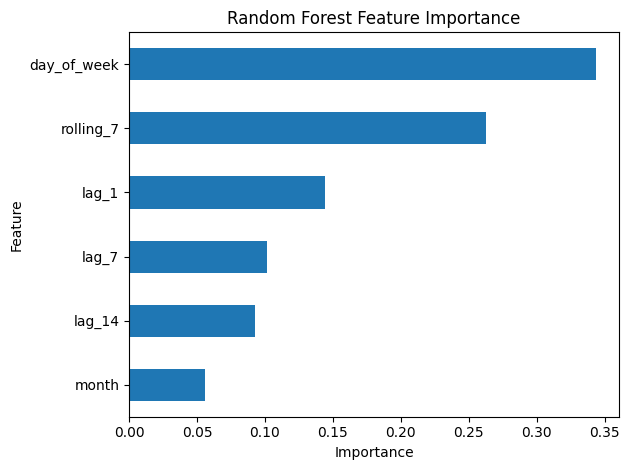

In [47]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(10,6))

importance.sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False
)

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel("Importance")

plt.tight_layout()
plt.show()

In [48]:
final_sarima = SARIMAX(
    forecast_data,
    order=(1,1,1),
    seasonal_order=(1,1,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_sarima_fit = final_sarima.fit(
    disp=False
)

In [49]:
future_30 = final_sarima_fit.forecast(
    steps=30
)

future_forecast = pd.DataFrame({
    "date": future_30.index,
    "forecast_demand": future_30.values
})

display(future_forecast)

,date,forecast_demand
0,2025-01-02,7366.689967
1,2025-01-03,7584.764607
2,2025-01-04,10760.737044
3,2025-01-05,10693.146797
4,2025-01-06,7708.786737
5,2025-01-07,6617.532042
6,2025-01-08,7941.736267
7,2025-01-09,7568.699342
8,2025-01-10,7442.342785
9,2025-01-11,10721.408361


In [50]:
future_peaks = future_forecast.sort_values(
    "forecast_demand",
    ascending=False
)

display(
    future_peaks.head(10)
)

,date,forecast_demand
23,2025-01-25,10770.464434
2,2025-01-04,10760.737044
16,2025-01-18,10744.468914
24,2025-01-26,10741.841216
9,2025-01-11,10721.408361
17,2025-01-19,10715.763510
3,2025-01-05,10693.146797
10,2025-01-12,10690.955890
6,2025-01-08,7941.736267
27,2025-01-29,7854.485486


In [51]:
kpi_table = pd.DataFrame({
    "KPI": [
        "Total Records",
        "Total Demand",
        "Total Revenue",
        "Total Ingredient Cost",
        "Total Gross Margin",
        "Average Daily Demand",
        "Maximum Daily Demand",
        "Minimum Daily Demand",
        "Average Selling Price",
        "Average Margin Percentage",
        "SARIMA MAE",
        "SARIMA RMSE",
        "SARIMA R2",
        "SARIMA MAPE",
        "Random Forest MAE",
        "Random Forest RMSE",
        "Random Forest R2",
        "Random Forest MAPE"
    ],
    "Value": [
        len(df),
        df["quantity_sold"].sum(),
        df["revenue"].sum(),
        df["ingredient_cost"].sum(),
        df["gross_margin"].sum(),
        daily["demand"].mean(),
        daily["demand"].max(),
        daily["demand"].min(),
        df["actual_selling_price"].mean(),
        df["margin_percentage"].mean(),
        sarima_mae,
        sarima_rmse,
        sarima_r2,
        sarima_mape,
        rf_mae,
        rf_rmse,
        rf_r2,
        rf_mape
    ]
})

display(
    kpi_table.round(2)
)

,KPI,Value
0,Total Records,10000.00
1,Total Demand,2860004.00
2,Total Revenue,32713418.10
3,Total Ingredient Cost,7828735.20
4,Total Gross Margin,24884682.90
5,Average Daily Demand,7792.93
6,Maximum Daily Demand,17081.00
7,Minimum Daily Demand,2395.00
8,Average Selling Price,18.86
9,Average Margin Percentage,70.45


In [52]:
!pip install plotly -q


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# CAFÉ & RESTAURANT DEMAND FORECASTING DASHBOARD

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import webbrowser
import os

# Browser renderer
pio.renderers.default = "browser"


# DATA PREPARATION

# Revenue
if "revenue" not in df.columns:
    df["revenue"] = (
        df["actual_selling_price"]
        * df["quantity_sold"]
    )


# Gross margin
if "gross_margin" not in df.columns:
    df["gross_margin"] = (
        (
            df["actual_selling_price"]
            - df["typical_ingredient_cost"]
        )
        * df["quantity_sold"]
    )


# ADDITIONAL BUSINESS INTELLIGENCE ANALYSIS

# ------------------------------------------------------------
# 1. TOP 10 MOST ORDERED DISHES
# ------------------------------------------------------------

menu_demand = (
    df.groupby("menu_item_name")["quantity_sold"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)


# ------------------------------------------------------------
# 2. TOP 10 DISHES BY REVENUE
# ------------------------------------------------------------

menu_revenue = (
    df.groupby("menu_item_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)


# ------------------------------------------------------------
# 3. PROMOTION ANALYSIS
# ------------------------------------------------------------

promotion_analysis = (
    df.groupby("has_promotion")["quantity_sold"]
    .mean()
)

promotion_analysis.index = promotion_analysis.index.map(
    {
        True: "Promotion",
        False: "No Promotion"
    }
)


# ------------------------------------------------------------
# 4. SPECIAL EVENT ANALYSIS
# ------------------------------------------------------------

event_analysis = (
    df.groupby("special_event")["quantity_sold"]
    .mean()
)

event_analysis.index = event_analysis.index.map(
    {
        True: "Special Event",
        False: "Normal Day"
    }
)


# ------------------------------------------------------------
# 5. WEATHER ANALYSIS
# ------------------------------------------------------------

weather_analysis = (
    df.groupby("weather_condition")["quantity_sold"]
    .mean()
    .sort_values(ascending=False)
)


# ------------------------------------------------------------
# 6. MONTHLY REVENUE
# ------------------------------------------------------------

df["dashboard_month"] = (
    df["date"]
    .dt.to_period("M")
    .astype(str)
)

monthly_revenue = (
    df.groupby("dashboard_month")["revenue"]
    .sum()
)


# BUSINESS INSIGHT VALUES

top_menu_item = menu_demand.idxmax()
top_menu_demand = menu_demand.max()

top_revenue_item = menu_revenue.idxmax()
top_revenue_value = menu_revenue.max()

busiest_day = day_analysis["mean"].idxmax()
busiest_day_demand = day_analysis["mean"].max()

highest_weather = weather_analysis.idxmax()
highest_weather_demand = weather_analysis.max()


# KPI VALUES

total_demand = df["quantity_sold"].sum()

total_revenue = df["revenue"].sum()

total_margin = df["gross_margin"].sum()

average_daily_demand = daily["demand"].mean()

peak_daily_demand = daily["demand"].max()


# DASHBOARD

dashboard = make_subplots(

    rows=8,
    cols=2,

    row_heights=[
        0.08,
        0.13,
        0.13,
        0.13,
        0.13,
        0.13,
        0.13,
        0.14
    ],

    vertical_spacing=0.045,

    horizontal_spacing=0.08,

    specs=[

        # ----------------------------------------------------
        # ROW 1 - KPI CARDS
        # ----------------------------------------------------

        [
            {"type": "indicator"},
            {"type": "indicator"}
        ],

        # ----------------------------------------------------
        # ROW 2 - EXISTING
        # ----------------------------------------------------

        [
            {"type": "scatter"},
            {"type": "scatter"}
        ],

        # ----------------------------------------------------
        # ROW 3 - EXISTING
        # ----------------------------------------------------

        [
            {"type": "bar"},
            {"type": "bar"}
        ],

        # ----------------------------------------------------
        # ROW 4 - EXISTING
        # ----------------------------------------------------

        [
            {"type": "bar"},
            {"type": "scatter"}
        ],

        # ----------------------------------------------------
        # ROW 5 - EXISTING
        # ----------------------------------------------------

        [
            {"type": "scatter"},
            {"type": "table"}
        ],

        # ----------------------------------------------------
        # ROW 6 - NEW MENU ANALYSIS
        # ----------------------------------------------------

        [
            {"type": "bar"},
            {"type": "bar"}
        ],

        # ----------------------------------------------------
        # ROW 7 - NEW BUSINESS ANALYSIS
        # ----------------------------------------------------

        [
            {"type": "bar"},
            {"type": "bar"}
        ],

        # ----------------------------------------------------
        # ROW 8 - NEW BUSINESS / SEASONAL ANALYSIS
        # ----------------------------------------------------

        [
            {"type": "bar"},
            {"type": "scatter"}
        ]
    ],

    subplot_titles=(

        # Row 1
        "",
        "",

        # Row 2
        "Daily Demand Trend",
        "Monthly Demand",

        # Row 3
        "Average Demand by Day of Week",
        "Average Demand by Meal Type",

        # Row 4
        "Demand by Restaurant Type",
        "Actual vs Forecast Demand",

        # Row 5
        "Next 30-Day Demand Forecast",
        "Demand Summary",

        # Row 6
        "Top 10 Most Ordered Dishes",
        "Top 10 Dishes by Revenue",

        # Row 7
        "Promotion vs No Promotion",
        "Special Event vs Normal Day",

        # Row 8
        "Average Demand by Weather",
        "Monthly Revenue / Seasonal Sales Trend"
    )
)


# ROW 1
# KPI 1 — TOTAL DEMAND

dashboard.add_trace(

    go.Indicator(

        mode="number",

        value=total_demand,

        title={
            "text": "<b>TOTAL DEMAND</b>"
        },

        number={
            "valueformat": ",.0f",
            "font": {
                "size": 30
            }
        }
    ),

    row=1,
    col=1
)


# KPI 2 — TOTAL REVENUE

dashboard.add_trace(

    go.Indicator(

        mode="number",

        value=total_revenue,

        title={
            "text": "<b>TOTAL REVENUE</b>"
        },

        number={
            "prefix": "$",
            "valueformat": ",.2f",
            "font": {
                "size": 30
            }
        }
    ),

    row=1,
    col=2
)


# ROW 2
# DAILY DEMAND TREND

dashboard.add_trace(

    go.Scatter(

        x=daily["date"],

        y=daily["demand"],

        mode="lines",

        name="Daily Demand",

        line=dict(
            width=2
        ),

        hovertemplate=
        "<b>Date:</b> %{x}<br>" +
        "<b>Demand:</b> %{y:,.0f}" +
        "<extra></extra>"
    ),

    row=2,
    col=1
)


# Date range slider
dashboard.update_xaxes(

    rangeslider=dict(
        visible=True
    ),

    row=2,
    col=1
)


# MONTHLY DEMAND

# Detect month column from existing monthly dataframe
monthly_month_column = None

for column in monthly.columns:

    if column.lower() in [
        "month",
        "month_name",
        "date",
        "period"
    ]:

        monthly_month_column = column
        break


if monthly_month_column is None:

    non_numeric_columns = (
        monthly
        .select_dtypes(exclude="number")
        .columns
    )

    if len(non_numeric_columns) > 0:

        monthly_month_column = (
            non_numeric_columns[0]
        )


if monthly_month_column is None:

    monthly_month_column = monthly.columns[0]


# Detect demand column
monthly_demand_column = None

for column in monthly.columns:

    if column.lower() in [
        "quantity_sold",
        "demand",
        "sum"
    ]:

        monthly_demand_column = column
        break


if monthly_demand_column is None:

    numeric_columns = (
        monthly
        .select_dtypes(include="number")
        .columns
    )

    monthly_demand_column = (
        numeric_columns[-1]
    )


dashboard.add_trace(

    go.Scatter(

        x=monthly[
            monthly_month_column
        ],

        y=monthly[
            monthly_demand_column
        ],

        mode="lines+markers",

        name="Monthly Demand",

        line=dict(
            width=2
        ),

        hovertemplate=
        "<b>Month:</b> %{x}<br>" +
        "<b>Demand:</b> %{y:,.0f}" +
        "<extra></extra>"
    ),

    row=2,
    col=2
)


# ROW 3
# DAY OF WEEK

dashboard.add_trace(

    go.Bar(

        x=day_analysis.index,

        y=day_analysis["mean"],

        name="Average Daily Demand",

        text=day_analysis["mean"].round(1),

        textposition="outside",

        hovertemplate=
        "<b>Day:</b> %{x}<br>" +
        "<b>Average Demand:</b> %{y:.1f}" +
        "<extra></extra>"
    ),

    row=3,
    col=1
)


# MEAL TYPE

dashboard.add_trace(

    go.Bar(

        x=meal_analysis.index,

        y=meal_analysis[
            "average_demand"
        ],

        name="Meal Demand",

        text=meal_analysis[
            "average_demand"
        ].round(1),

        textposition="outside",

        hovertemplate=
        "<b>Meal:</b> %{x}<br>" +
        "<b>Average Demand:</b> %{y:.1f}" +
        "<extra></extra>"
    ),

    row=3,
    col=2
)


# ROW 4
# RESTAURANT TYPE

dashboard.add_trace(

    go.Bar(

        x=restaurant_analysis.index,

        y=restaurant_analysis[
            "demand"
        ],

        name="Restaurant Demand",

        text=restaurant_analysis[
            "demand"
        ].round(0),

        textposition="outside",

        hovertemplate=
        "<b>Restaurant Type:</b> %{x}<br>" +
        "<b>Total Demand:</b> %{y:,.0f}" +
        "<extra></extra>"
    ),

    row=4,
    col=1
)


# ACTUAL VS FORECAST

dashboard.add_trace(

    go.Scatter(

        x=test.index,

        y=test.values,

        mode="lines",

        name="Actual Demand",

        line=dict(
            width=2
        ),

        hovertemplate=
        "<b>Date:</b> %{x}<br>" +
        "<b>Actual:</b> %{y:,.0f}" +
        "<extra></extra>"
    ),

    row=4,
    col=2
)


dashboard.add_trace(

    go.Scatter(

        x=sarima_forecast.index,

        y=sarima_forecast.values,

        mode="lines",

        name="SARIMA Forecast",

        line=dict(
            width=2,
            dash="dash"
        ),

        hovertemplate=
        "<b>Date:</b> %{x}<br>" +
        "<b>Forecast:</b> %{y:,.0f}" +
        "<extra></extra>"
    ),

    row=4,
    col=2
)


# ROW 5
# 30-DAY FORECAST

dashboard.add_trace(

    go.Scatter(

        x=future_forecast["date"],

        y=future_forecast[
            "forecast_demand"
        ],

        mode="lines+markers",

        name="30-Day Forecast",

        line=dict(
            width=2
        ),

        hovertemplate=
        "<b>Date:</b> %{x}<br>" +
        "<b>Forecast:</b> %{y:,.0f}" +
        "<extra></extra>"
    ),

    row=5,
    col=1
)


# SUMMARY TABLE

summary_values = [

    [
        "Total Demand",
        f"{total_demand:,.0f}"
    ],

    [
        "Total Revenue",
        f"${total_revenue:,.2f}"
    ],

    [
        "Gross Margin",
        f"${total_margin:,.2f}"
    ],

    [
        "Average Daily Demand",
        f"{average_daily_demand:,.1f}"
    ],

    [
        "Peak Daily Demand",
        f"{peak_daily_demand:,.0f}"
    ],

    [
        "Busiest Day",
        f"{busiest_day}"
    ],

    [
        "Most Ordered Dish",
        f"{top_menu_item}"
    ],

    [
        "Top Revenue Dish",
        f"{top_revenue_item}"
    ],

    [
        "Highest-Demand Weather",
        f"{highest_weather}"
    ]
]


dashboard.add_trace(

    go.Table(

        header=dict(

            values=[
                "<b>KPI</b>",
                "<b>Value</b>"
            ],

            align="center",

            font=dict(
                size=13
            )
        ),

        cells=dict(

            values=[

                [
                    row[0]
                    for row in summary_values
                ],

                [
                    row[1]
                    for row in summary_values
                ]

            ],

            align="center",

            font=dict(
                size=11
            ),

            height=25
        )
    ),

    row=5,
    col=2
)


# ROW 6
# TOP 10 MOST ORDERED DISHES

dashboard.add_trace(

    go.Bar(

        x=menu_demand.values,

        y=menu_demand.index,

        orientation="h",

        name="Most Ordered Dishes",

        text=[
            f"{value:,.0f}"
            for value in menu_demand.values
        ],

        textposition="outside",

        hovertemplate=
        "<b>Dish:</b> %{y}<br>" +
        "<b>Quantity Sold:</b> %{x:,.0f}" +
        "<extra></extra>"
    ),

    row=6,
    col=1
)


# TOP 10 DISHES BY REVENUE

dashboard.add_trace(

    go.Bar(

        x=menu_revenue.values,

        y=menu_revenue.index,

        orientation="h",

        name="Top Revenue Dishes",

        text=[
            f"${value:,.0f}"
            for value in menu_revenue.values
        ],

        textposition="outside",

        hovertemplate=
        "<b>Dish:</b> %{y}<br>" +
        "<b>Revenue:</b> $%{x:,.2f}" +
        "<extra></extra>"
    ),

    row=6,
    col=2
)


# ROW 7
# PROMOTION VS NO PROMOTION

dashboard.add_trace(

    go.Bar(

        x=promotion_analysis.index,

        y=promotion_analysis.values,

        name="Promotion Analysis",

        text=[
            f"{value:,.1f}"
            for value in promotion_analysis.values
        ],

        textposition="outside",

        hovertemplate=
        "<b>Condition:</b> %{x}<br>" +
        "<b>Average Demand:</b> %{y:,.1f}" +
        "<extra></extra>"
    ),

    row=7,
    col=1
)


# SPECIAL EVENT VS NORMAL DAY

dashboard.add_trace(

    go.Bar(

        x=event_analysis.index,

        y=event_analysis.values,

        name="Special Event Analysis",

        text=[
            f"{value:,.1f}"
            for value in event_analysis.values
        ],

        textposition="outside",

        hovertemplate=
        "<b>Condition:</b> %{x}<br>" +
        "<b>Average Demand:</b> %{y:,.1f}" +
        "<extra></extra>"
    ),

    row=7,
    col=2
)


# ROW 8
# WEATHER ANALYSIS

dashboard.add_trace(

    go.Bar(

        x=weather_analysis.index,

        y=weather_analysis.values,

        name="Weather Demand",

        text=[
            f"{value:,.1f}"
            for value in weather_analysis.values
        ],

        textposition="outside",

        hovertemplate=
        "<b>Weather:</b> %{x}<br>" +
        "<b>Average Demand:</b> %{y:,.1f}" +
        "<extra></extra>"
    ),

    row=8,
    col=1
)


# MONTHLY REVENUE / SEASONAL SALES TREND

dashboard.add_trace(

    go.Scatter(

        x=monthly_revenue.index,

        y=monthly_revenue.values,

        mode="lines+markers",

        name="Monthly Revenue",

        line=dict(
            width=2
        ),

        marker=dict(
            size=7
        ),

        hovertemplate=
        "<b>Month:</b> %{x}<br>" +
        "<b>Revenue:</b> $%{y:,.2f}" +
        "<extra></extra>"
    ),

    row=8,
    col=2
)


# AXIS LABELS

# Row 2
dashboard.update_xaxes(
    title_text="Date",
    row=2,
    col=1
)

dashboard.update_yaxes(
    title_text="Quantity Sold",
    row=2,
    col=1
)

dashboard.update_xaxes(
    title_text="Month",
    row=2,
    col=2
)

dashboard.update_yaxes(
    title_text="Quantity Sold",
    row=2,
    col=2
)


# Row 3
dashboard.update_xaxes(
    title_text="Day of Week",
    row=3,
    col=1
)

dashboard.update_yaxes(
    title_text="Average Quantity Sold",
    row=3,
    col=1
)

dashboard.update_xaxes(
    title_text="Meal Type",
    row=3,
    col=2
)

dashboard.update_yaxes(
    title_text="Average Quantity Sold",
    row=3,
    col=2
)


# Row 4
dashboard.update_xaxes(
    title_text="Restaurant Type",
    row=4,
    col=1
)

dashboard.update_yaxes(
    title_text="Total Quantity Sold",
    row=4,
    col=1
)

dashboard.update_xaxes(
    title_text="Date",
    row=4,
    col=2
)

dashboard.update_yaxes(
    title_text="Quantity Sold",
    row=4,
    col=2
)


# Row 5
dashboard.update_xaxes(
    title_text="Date",
    row=5,
    col=1
)

dashboard.update_yaxes(
    title_text="Forecast Demand",
    row=5,
    col=1
)


# Row 6
dashboard.update_xaxes(
    title_text="Quantity Sold",
    row=6,
    col=1
)

dashboard.update_yaxes(
    title_text="Dish",
    row=6,
    col=1
)

dashboard.update_xaxes(
    title_text="Revenue",
    row=6,
    col=2
)

dashboard.update_yaxes(
    title_text="Dish",
    row=6,
    col=2
)


# Row 7
dashboard.update_xaxes(
    title_text="Promotion Status",
    row=7,
    col=1
)

dashboard.update_yaxes(
    title_text="Average Quantity Sold",
    row=7,
    col=1
)

dashboard.update_xaxes(
    title_text="Event Status",
    row=7,
    col=2
)

dashboard.update_yaxes(
    title_text="Average Quantity Sold",
    row=7,
    col=2
)


# Row 8
dashboard.update_xaxes(
    title_text="Weather Condition",
    row=8,
    col=1
)

dashboard.update_yaxes(
    title_text="Average Quantity Sold",
    row=8,
    col=1
)

dashboard.update_xaxes(
    title_text="Month",
    row=8,
    col=2
)

dashboard.update_yaxes(
    title_text="Revenue",
    row=8,
    col=2
)


# PROFESSIONAL DASHBOARD DESIGN

dashboard.update_layout(

    title={

        "text":
        "<b>Café & Restaurant Demand Forecasting Dashboard</b>"
        "<br>"
        "<sup>"
        "Demand | Sales | Menu Performance | Business Drivers | Forecasting"
        "</sup>",

        "x": 0.5,

        "xanchor": "center",

        "y": 0.99,

        "font": {
            "size": 28
        }
    },

    height=3600,

    width=1500,

    template="plotly_white",

    paper_bgcolor="#F7F3EE",

    plot_bgcolor="#FFFFFF",

    hovermode="closest",

    legend=dict(

        orientation="h",

        yanchor="bottom",

        y=1.01,

        xanchor="center",

        x=0.5,

        font=dict(
            size=12
        )
    ),

    margin=dict(

        l=80,

        r=80,

        t=170,

        b=80
    )
)


# SAVE DASHBOARD

dashboard_file = (
    "Cafe_Restaurant_Demand_Forecasting_Dashboard.html"
)

dashboard.write_html(

    dashboard_file,

    include_plotlyjs=True,

    full_html=True
)


# OPEN DASHBOARD

dashboard_path = os.path.abspath(
    dashboard_file
)

webbrowser.open(
    "file://" + dashboard_path
)

print(
    "Dashboard successfully created:"
)

print(
    dashboard_path
)

Dashboard successfully created:
c:\Users\Admin\Downloads\Correction of Soni_1134\Correction of Soni_1134\Completed file\Cafe_Restaurant_Demand_Forecasting_Dashboard.html
